# Süreçteki değişim normal dalgalanma mı?

Operasyon hem çevrim süresini hem paket kusurlarını izliyor. Her süre alt grubunda beş ardışık standart iş; kusur kontrolünde her gün değişen sayıda paket var. İlk 30 dönem referans, sonraki 10 dönem izleme. Süre, kusurlu paket payı ve paket başına toplam kusur aynı grafikle izlenemez.

**Karar:** Hangi ölçü için hangi kontrol grafiği kullanılmalı ve hangi izleme dönemleri araştırılmalı?

**Birim:** Sürede rasyonel alt grup; sayımda gün ve o gün incelenen paket miktarı.

**Yöntem:** Süre için X̄–R, kusurlu paket payı için p, paket başına toplam kusur için u seç. Önce referansın uygunluğunu kontrol et; izleme sınırını yeni sinyalle tekrar hesaplayarak sinyali örtme.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: İzlemede özel neden ekleniyor

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                   Ölçü         Değer
      Referans / izleme 30 / 10 dönem
         X̄ merkez · sn     20.162923
      R ortalaması · sn      2.131302
       p referans oranı       0.08013
       u referans oranı      0.082234
İncelenen günlük miktar       232–499

Yalnız üç-sigma sınır dışı sinyalleri
chart reference_flags        monitor_flags
    R              []                   []
 Xbar              [] [36, 37, 38, 39, 40]
    p              [] [36, 37, 38, 39, 40]
    u              [] [36, 37, 38, 39, 40]

Referanstan dondurulmuş sürekli ölçüm sınırları
 Xbar_LCL  Xbar_UCL    R_UCL
18.933162 21.392684 4.505571

Karar: Referans döneminde bu tek kurala göre sınır dışı sinyal yok. İzlemede sinyaller var: gün/alt grup kaynağını araştır; tolerans veya performans hedefiyle karıştırma.

Sınır: Bağımsız ve karşılaştırılabilir rasyonel alt gruplar; sürekli model için uygun dağılım ve n=5 sabitleri. p için binom, u için Poisson yaklaşımı; aşırı saçılım/kümelenme ayrıca incelenir. Yalnız

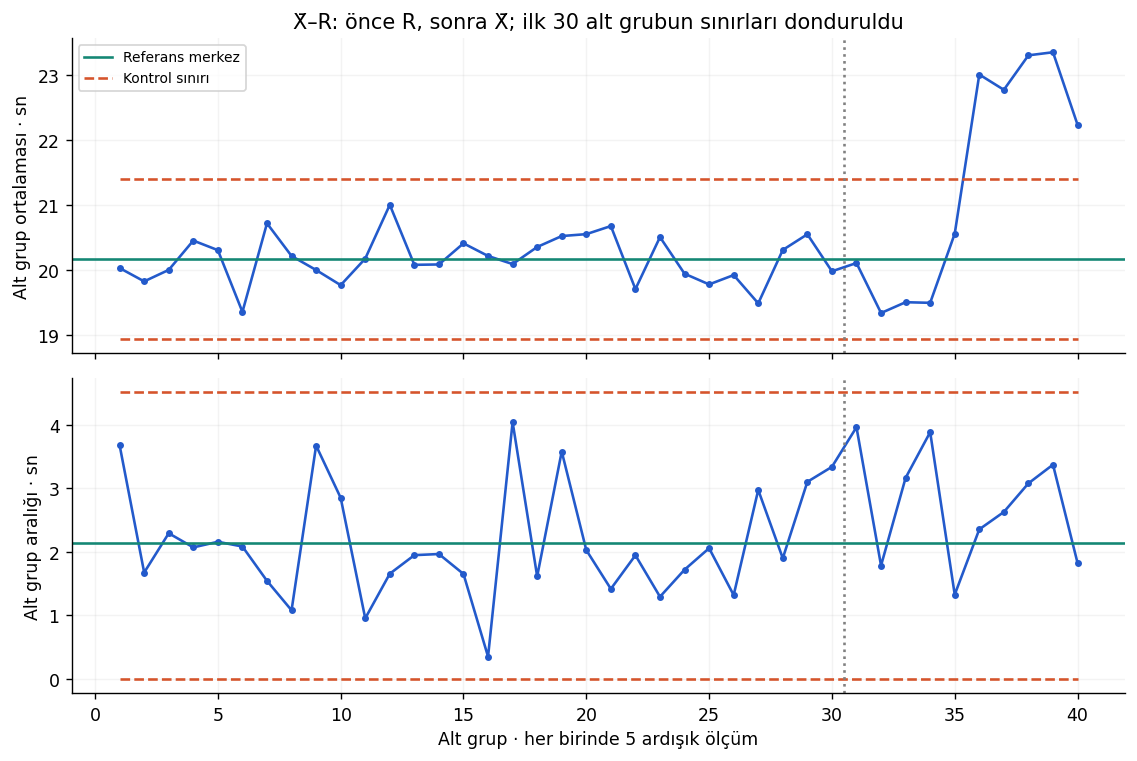

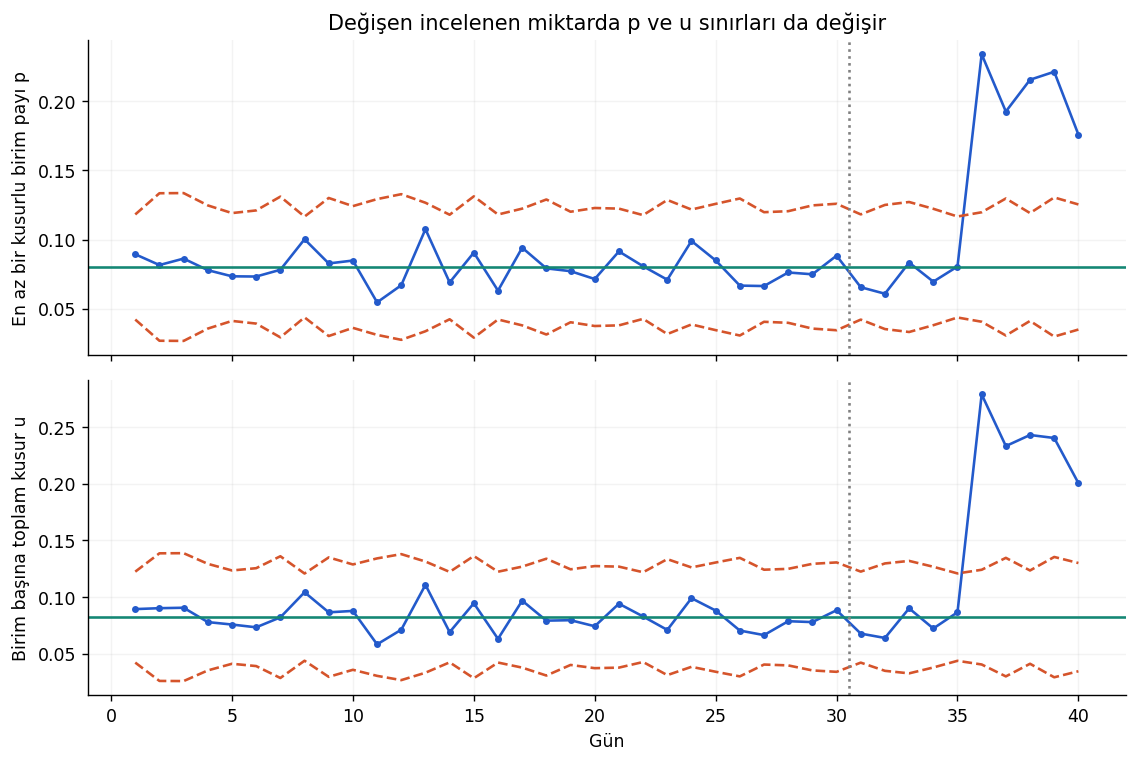

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def control(scenario='default'):
 rng=np.random.default_rng(260806);m,n=40,5;raw=rng.normal(20,1,(m,n));raw[35:]+=3 if scenario=='default' else 0;phase=np.array(['reference']*30+['monitor']*10);mean=raw.mean(axis=1);ranges=np.ptp(raw,axis=1);xbar=mean[:30].mean();rbar=ranges[:30].mean();xl,xu=xbar-.577*rbar,xbar+.577*rbar;ru=2.114*rbar;range_flags=np.where(ranges>ru)[0]+1;mean_flags=np.where((mean<xl)|(mean>xu))[0]+1
 sizes=rng.integers(220,501,m);d=[];defectives=[]
 for i,N in enumerate(sizes):
  events=rng.poisson(.08 if i<35 or scenario!='default' else .22,int(N));d.append(events.sum());defectives.append(np.sum(events>0))
 d=np.array(d);defectives=np.array(defectives);p=defectives/sizes;u=d/sizes;pbar=defectives[:30].sum()/sizes[:30].sum();ubar=d[:30].sum()/sizes[:30].sum();pl=np.maximum(0,pbar-3*np.sqrt(pbar*(1-pbar)/sizes));pu=np.minimum(1,pbar+3*np.sqrt(pbar*(1-pbar)/sizes));ul=np.maximum(0,ubar-3*np.sqrt(ubar/sizes));uu=ubar+3*np.sqrt(ubar/sizes);pf=np.where((p<pl)|(p>pu))[0]+1;uf=np.where((u<ul)|(u>uu))[0]+1
 continuous=pd.DataFrame({'subgroup':np.repeat(np.arange(1,m+1),n),'phase':np.repeat(phase,n),'within_group':np.tile(np.arange(1,n+1),m),'seconds':raw.ravel()});counts=pd.DataFrame({'day':np.arange(1,m+1),'phase':phase,'inspected':sizes,'defective_units':defectives,'total_defects':d});assert np.all(defectives<=sizes)and np.all(d>=defectives);limits=pd.DataFrame({'day':np.arange(1,m+1),'p':p,'p_LCL':pl,'p_UCL':pu,'u':u,'u_LCL':ul,'u_UCL':uu});days=np.arange(1,m+1)
 fig,axes=plt.subplots(2,1,figsize=(9.2,6.2),sharex=True)
 for ax,vals,center,low,high,label in [(axes[0],mean,xbar,np.full(m,xl),np.full(m,xu),'Alt grup ortalaması · sn'),(axes[1],ranges,rbar,np.zeros(m),np.full(m,ru),'Alt grup aralığı · sn')]:
  ax.plot(days,vals,'o-',ms=3,color='#235ACB');ax.axhline(center,color='#148774',label='Referans merkez');ax.plot(days,low,'--',color='#D5542B');ax.plot(days,high,'--',color='#D5542B',label='Kontrol sınırı');ax.axvline(30.5,color='gray',ls=':');ax.set_ylabel(label)
 axes[0].set_title('X̄–R: önce R, sonra X̄; ilk 30 alt grubun sınırları donduruldu');axes[0].legend(fontsize=8);axes[1].set_xlabel('Alt grup · her birinde 5 ardışık ölçüm');fig.tight_layout()
 fig2,axes2=plt.subplots(2,1,figsize=(9.2,6.2),sharex=True)
 for ax,vals,center,low,high,label in [(axes2[0],p,pbar,pl,pu,'En az bir kusurlu birim payı p'),(axes2[1],u,ubar,ul,uu,'Birim başına toplam kusur u')]:
  ax.plot(days,vals,'o-',ms=3,color='#235ACB');ax.axhline(center,color='#148774');ax.plot(days,low,'--',color='#D5542B');ax.plot(days,high,'--',color='#D5542B');ax.axvline(30.5,color='gray',ls=':');ax.set_ylabel(label)
 axes2[0].set_title('Değişen incelenen miktarda p ve u sınırları da değişir');axes2[1].set_xlabel('Gün');fig2.tight_layout()
 signals=pd.DataFrame({'chart':['R','Xbar','p','u'],'reference_flags':[str([int(x)for x in f if x<=30])for f in [range_flags,mean_flags,pf,uf]],'monitor_flags':[str([int(x)for x in f if x>30])for f in [range_flags,mean_flags,pf,uf]]});reference_any=any(np.any(f<=30)for f in [range_flags,mean_flags,pf,uf]);decision=('Referans döneminde sınır dışı noktalar var; bu sınırları kararlı süreç kanıtı gibi kullanma, önce referansı araştır. 'if reference_any else'Referans döneminde bu tek kurala göre sınır dışı sinyal yok. ')+('İzlemede sinyaller var: gün/alt grup kaynağını araştır; tolerans veya performans hedefiyle karıştırma.'if any(np.any(f>30)for f in [range_flags,mean_flags,pf,uf])else'İzlemede bu tek kurala göre sinyal yok; bu, bütün özel nedenlerin dışlandığı anlamına gelmez.')
 return dict(metrics={'Referans / izleme':'30 / 10 dönem','X̄ merkez · sn':xbar,'R ortalaması · sn':rbar,'p referans oranı':pbar,'u referans oranı':ubar,'İncelenen günlük miktar':f'{sizes.min()}–{sizes.max()}'},tables=[tbl(signals,'Yalnız üç-sigma sınır dışı sinyalleri'),tbl(pd.DataFrame({'Xbar_LCL':[xl],'Xbar_UCL':[xu],'R_UCL':[ru]}),'Referanstan dondurulmuş sürekli ölçüm sınırları')],figures=[('R değişkenliği denetlenmeden ortalama grafiği tek başına yorumlanmaz. Sınırlar yeni ölçümler geldikçe yeniden fit edilmedi.',fig),('p kusurlu birim payı; u toplam kusur/birim. Aynı birimde birden fazla kusur olabilir.',fig2)],frames={'sure_alt_gruplari':continuous,'sayimlar':counts,'p_u_sinirlari':limits},steps=['Önce veri türü: n=5 rasyonel alt grupta sürekli süre → X̄–R; birimin uygun/uygunsuzluğu → p; birim başına toplam kusur → u.','İlk 30 dönemde X̄̄, R̄, p̄=Σkusurlu/Σn ve ū=Σkusur/Σn tahmin et. İzleme için bu referansı dondur.','n=5 için X̄ sınırları X̄̄±0,577R̄; R sınırları [0,2,114R̄]. p/u sınırları o günün n değerini kullanır.','Önce referans sinyalini, ardından izleme sinyalini araştır. Sabit n için np, sabit maruziyette c düşünülebilir; değişken n durumunda ham sayıyı tek sabit sınırla kıyaslama.'],decision=decision,diagnostics={'Xbar_limits':[float(xl),float(xu)],'R_upper':float(ru),'pbar':float(pbar),'ubar':float(ubar),'mean_flags':mean_flags.tolist(),'range_flags':range_flags.tolist(),'p_flags':pf.tolist(),'u_flags':uf.tolist(),'reference_any_signal':reference_any,'reference_n':30},limit='Bağımsız ve karşılaştırılabilir rasyonel alt gruplar; sürekli model için uygun dağılım ve n=5 sabitleri. p için binom, u için Poisson yaklaşımı; aşırı saçılım/kümelenme ayrıca incelenir. Yalnız üç-sigma sınır dışı kuralı; bütün koşu kuralları, X̄–S veya risk ayarlı grafikler uygulanmaz.')

result=control('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: Aynı süreç sürüyor

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                   Ölçü         Değer
      Referans / izleme 30 / 10 dönem
         X̄ merkez · sn     20.162923
      R ortalaması · sn      2.131302
       p referans oranı       0.08013
       u referans oranı      0.082234
İncelenen günlük miktar       232–499

Yalnız üç-sigma sınır dışı sinyalleri
chart reference_flags monitor_flags
    R              []            []
 Xbar              []            []
    p              []            []
    u              []            []

Referanstan dondurulmuş sürekli ölçüm sınırları
 Xbar_LCL  Xbar_UCL    R_UCL
18.933162 21.392684 4.505571

Karar: Referans döneminde bu tek kurala göre sınır dışı sinyal yok. İzlemede bu tek kurala göre sinyal yok; bu, bütün özel nedenlerin dışlandığı anlamına gelmez.

Sınır: Bağımsız ve karşılaştırılabilir rasyonel alt gruplar; sürekli model için uygun dağılım ve n=5 sabitleri. p için binom, u için Poisson yaklaşımı; aşırı saçılım/kümelenme ayrıca incelenir. Yalnız üç-sigma sınır dışı kuralı; bütün koşu kura

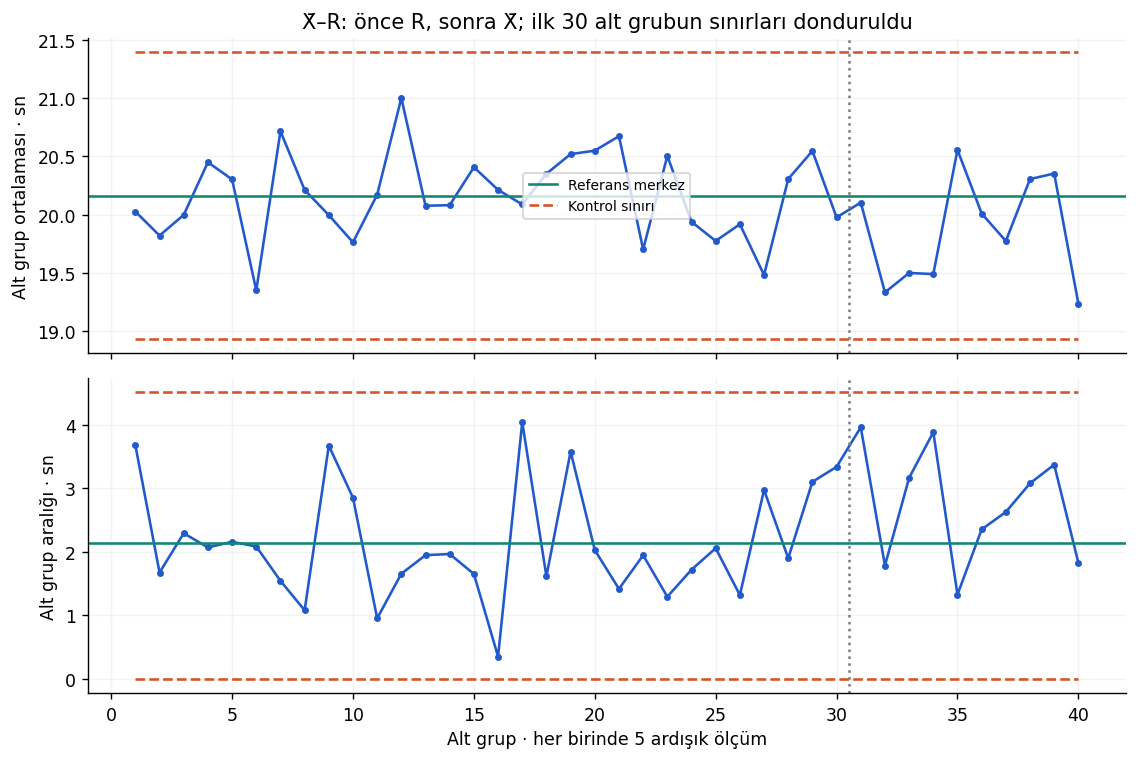

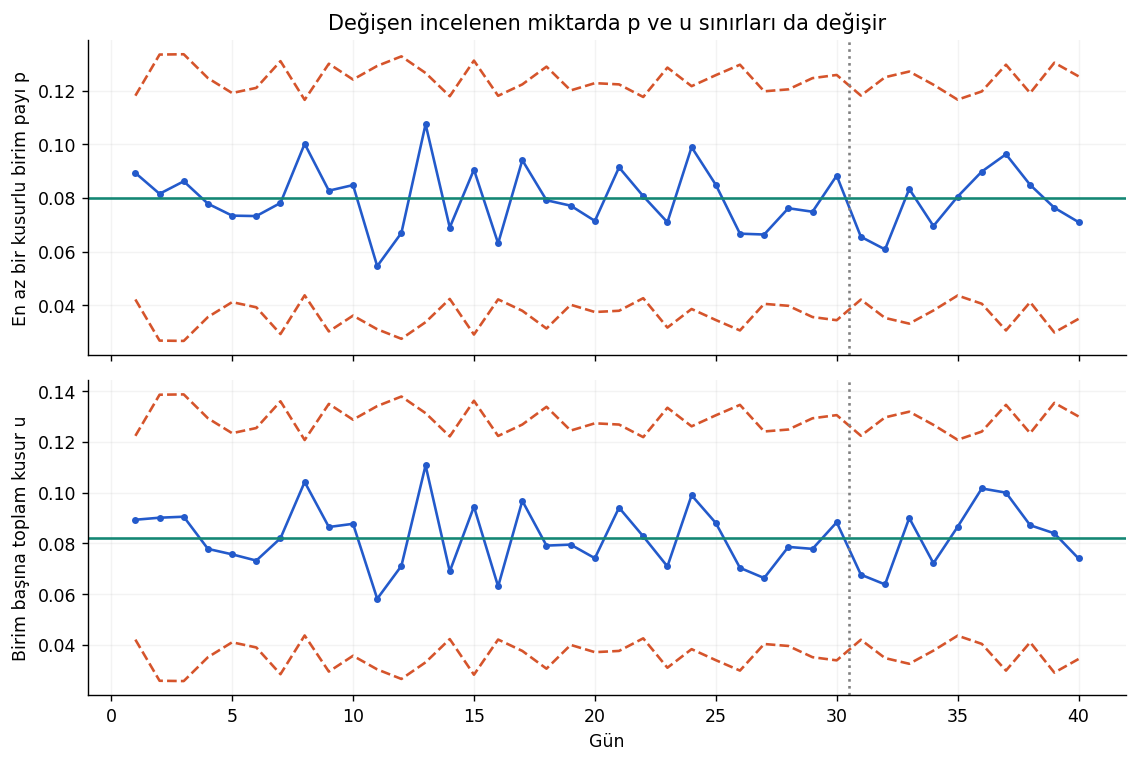

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def control(scenario='default'):
 rng=np.random.default_rng(260806);m,n=40,5;raw=rng.normal(20,1,(m,n));raw[35:]+=3 if scenario=='default' else 0;phase=np.array(['reference']*30+['monitor']*10);mean=raw.mean(axis=1);ranges=np.ptp(raw,axis=1);xbar=mean[:30].mean();rbar=ranges[:30].mean();xl,xu=xbar-.577*rbar,xbar+.577*rbar;ru=2.114*rbar;range_flags=np.where(ranges>ru)[0]+1;mean_flags=np.where((mean<xl)|(mean>xu))[0]+1
 sizes=rng.integers(220,501,m);d=[];defectives=[]
 for i,N in enumerate(sizes):
  events=rng.poisson(.08 if i<35 or scenario!='default' else .22,int(N));d.append(events.sum());defectives.append(np.sum(events>0))
 d=np.array(d);defectives=np.array(defectives);p=defectives/sizes;u=d/sizes;pbar=defectives[:30].sum()/sizes[:30].sum();ubar=d[:30].sum()/sizes[:30].sum();pl=np.maximum(0,pbar-3*np.sqrt(pbar*(1-pbar)/sizes));pu=np.minimum(1,pbar+3*np.sqrt(pbar*(1-pbar)/sizes));ul=np.maximum(0,ubar-3*np.sqrt(ubar/sizes));uu=ubar+3*np.sqrt(ubar/sizes);pf=np.where((p<pl)|(p>pu))[0]+1;uf=np.where((u<ul)|(u>uu))[0]+1
 continuous=pd.DataFrame({'subgroup':np.repeat(np.arange(1,m+1),n),'phase':np.repeat(phase,n),'within_group':np.tile(np.arange(1,n+1),m),'seconds':raw.ravel()});counts=pd.DataFrame({'day':np.arange(1,m+1),'phase':phase,'inspected':sizes,'defective_units':defectives,'total_defects':d});assert np.all(defectives<=sizes)and np.all(d>=defectives);limits=pd.DataFrame({'day':np.arange(1,m+1),'p':p,'p_LCL':pl,'p_UCL':pu,'u':u,'u_LCL':ul,'u_UCL':uu});days=np.arange(1,m+1)
 fig,axes=plt.subplots(2,1,figsize=(9.2,6.2),sharex=True)
 for ax,vals,center,low,high,label in [(axes[0],mean,xbar,np.full(m,xl),np.full(m,xu),'Alt grup ortalaması · sn'),(axes[1],ranges,rbar,np.zeros(m),np.full(m,ru),'Alt grup aralığı · sn')]:
  ax.plot(days,vals,'o-',ms=3,color='#235ACB');ax.axhline(center,color='#148774',label='Referans merkez');ax.plot(days,low,'--',color='#D5542B');ax.plot(days,high,'--',color='#D5542B',label='Kontrol sınırı');ax.axvline(30.5,color='gray',ls=':');ax.set_ylabel(label)
 axes[0].set_title('X̄–R: önce R, sonra X̄; ilk 30 alt grubun sınırları donduruldu');axes[0].legend(fontsize=8);axes[1].set_xlabel('Alt grup · her birinde 5 ardışık ölçüm');fig.tight_layout()
 fig2,axes2=plt.subplots(2,1,figsize=(9.2,6.2),sharex=True)
 for ax,vals,center,low,high,label in [(axes2[0],p,pbar,pl,pu,'En az bir kusurlu birim payı p'),(axes2[1],u,ubar,ul,uu,'Birim başına toplam kusur u')]:
  ax.plot(days,vals,'o-',ms=3,color='#235ACB');ax.axhline(center,color='#148774');ax.plot(days,low,'--',color='#D5542B');ax.plot(days,high,'--',color='#D5542B');ax.axvline(30.5,color='gray',ls=':');ax.set_ylabel(label)
 axes2[0].set_title('Değişen incelenen miktarda p ve u sınırları da değişir');axes2[1].set_xlabel('Gün');fig2.tight_layout()
 signals=pd.DataFrame({'chart':['R','Xbar','p','u'],'reference_flags':[str([int(x)for x in f if x<=30])for f in [range_flags,mean_flags,pf,uf]],'monitor_flags':[str([int(x)for x in f if x>30])for f in [range_flags,mean_flags,pf,uf]]});reference_any=any(np.any(f<=30)for f in [range_flags,mean_flags,pf,uf]);decision=('Referans döneminde sınır dışı noktalar var; bu sınırları kararlı süreç kanıtı gibi kullanma, önce referansı araştır. 'if reference_any else'Referans döneminde bu tek kurala göre sınır dışı sinyal yok. ')+('İzlemede sinyaller var: gün/alt grup kaynağını araştır; tolerans veya performans hedefiyle karıştırma.'if any(np.any(f>30)for f in [range_flags,mean_flags,pf,uf])else'İzlemede bu tek kurala göre sinyal yok; bu, bütün özel nedenlerin dışlandığı anlamına gelmez.')
 return dict(metrics={'Referans / izleme':'30 / 10 dönem','X̄ merkez · sn':xbar,'R ortalaması · sn':rbar,'p referans oranı':pbar,'u referans oranı':ubar,'İncelenen günlük miktar':f'{sizes.min()}–{sizes.max()}'},tables=[tbl(signals,'Yalnız üç-sigma sınır dışı sinyalleri'),tbl(pd.DataFrame({'Xbar_LCL':[xl],'Xbar_UCL':[xu],'R_UCL':[ru]}),'Referanstan dondurulmuş sürekli ölçüm sınırları')],figures=[('R değişkenliği denetlenmeden ortalama grafiği tek başına yorumlanmaz. Sınırlar yeni ölçümler geldikçe yeniden fit edilmedi.',fig),('p kusurlu birim payı; u toplam kusur/birim. Aynı birimde birden fazla kusur olabilir.',fig2)],frames={'sure_alt_gruplari':continuous,'sayimlar':counts,'p_u_sinirlari':limits},steps=['Önce veri türü: n=5 rasyonel alt grupta sürekli süre → X̄–R; birimin uygun/uygunsuzluğu → p; birim başına toplam kusur → u.','İlk 30 dönemde X̄̄, R̄, p̄=Σkusurlu/Σn ve ū=Σkusur/Σn tahmin et. İzleme için bu referansı dondur.','n=5 için X̄ sınırları X̄̄±0,577R̄; R sınırları [0,2,114R̄]. p/u sınırları o günün n değerini kullanır.','Önce referans sinyalini, ardından izleme sinyalini araştır. Sabit n için np, sabit maruziyette c düşünülebilir; değişken n durumunda ham sayıyı tek sabit sınırla kıyaslama.'],decision=decision,diagnostics={'Xbar_limits':[float(xl),float(xu)],'R_upper':float(ru),'pbar':float(pbar),'ubar':float(ubar),'mean_flags':mean_flags.tolist(),'range_flags':range_flags.tolist(),'p_flags':pf.tolist(),'u_flags':uf.tolist(),'reference_any_signal':reference_any,'reference_n':30},limit='Bağımsız ve karşılaştırılabilir rasyonel alt gruplar; sürekli model için uygun dağılım ve n=5 sabitleri. p için binom, u için Poisson yaklaşımı; aşırı saçılım/kümelenme ayrıca incelenir. Yalnız üç-sigma sınır dışı kuralı; bütün koşu kuralları, X̄–S veya risk ayarlı grafikler uygulanmaz.')

result=control('stable')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

Kararlı senaryoya geç. Sinyal yok demenin neyi kanıtlamadığını yaz. İki senaryoda da sınırların ilk 30 dönemden geldiğini kontrol et.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
